In [149]:

import os

print(os.path.exists("/content/Sample - Superstore.csv"))
print(os.path.exists("/content/archive.zip"))


True
True


In [150]:

import zipfile

with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [151]:

import pandas as pd

superstore_df = pd.read_csv(
    "/content/Sample - Superstore.csv",
    encoding="cp1252"
)

display(superstore_df.head())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [152]:

print("Total rows and columns:", superstore_df.shape)

print("\nColumn names:")
print(superstore_df.columns.tolist())

print("\nData types:")
print(superstore_df.dtypes)

print("\nMissing values:")
print(superstore_df.isnull().sum())


Total rows and columns: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Custome

In [153]:

# Select numerical columns
numeric_data = superstore_df.select_dtypes(include="number")

# Calculate descriptive statistics
print("Mean:")
print(numeric_data.mean())

print("\nMedian:")
print(numeric_data.median())

print("\nMode:")
print(numeric_data.mode().iloc[0])

print("\nStandard Deviation:")
print(numeric_data.std())


Mean:
Row ID          4997.500000
Postal Code    55190.379428
Sales            229.858001
Quantity           3.789574
Discount           0.156203
Profit            28.656896
dtype: float64

Median:
Row ID          4997.5000
Postal Code    56430.5000
Sales             54.4900
Quantity           3.0000
Discount           0.2000
Profit             8.6665
dtype: float64

Mode:
Row ID             1.00
Postal Code    10035.00
Sales             12.96
Quantity           3.00
Discount           0.00
Profit             0.00
Name: 0, dtype: float64

Standard Deviation:
Row ID          2885.163629
Postal Code    32063.693350
Sales            623.245101
Quantity           2.225110
Discount           0.206452
Profit           234.260108
dtype: float64


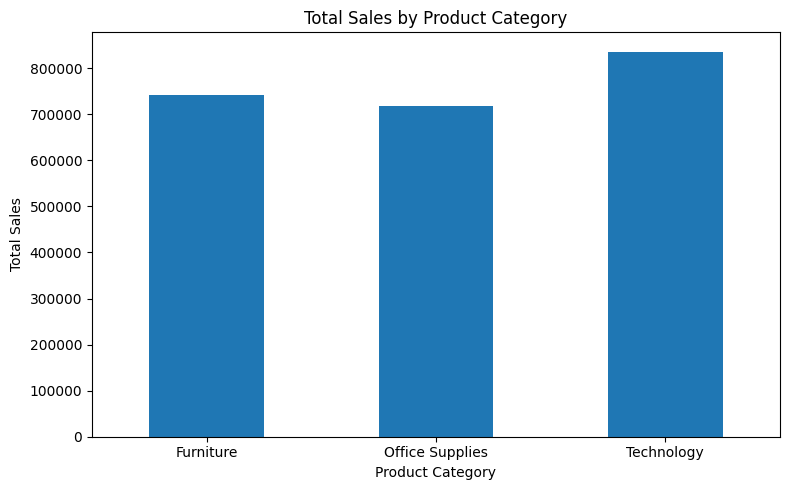

In [154]:

import matplotlib.pyplot as plt

# Calculate total sales for each category
category_sales = superstore_df.groupby("Category")["Sales"].sum()

# Create a bar chart
category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [155]:

print(category_sales.sort_values(ascending=False))


Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [156]:

top_products = (
    superstore_df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)


Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


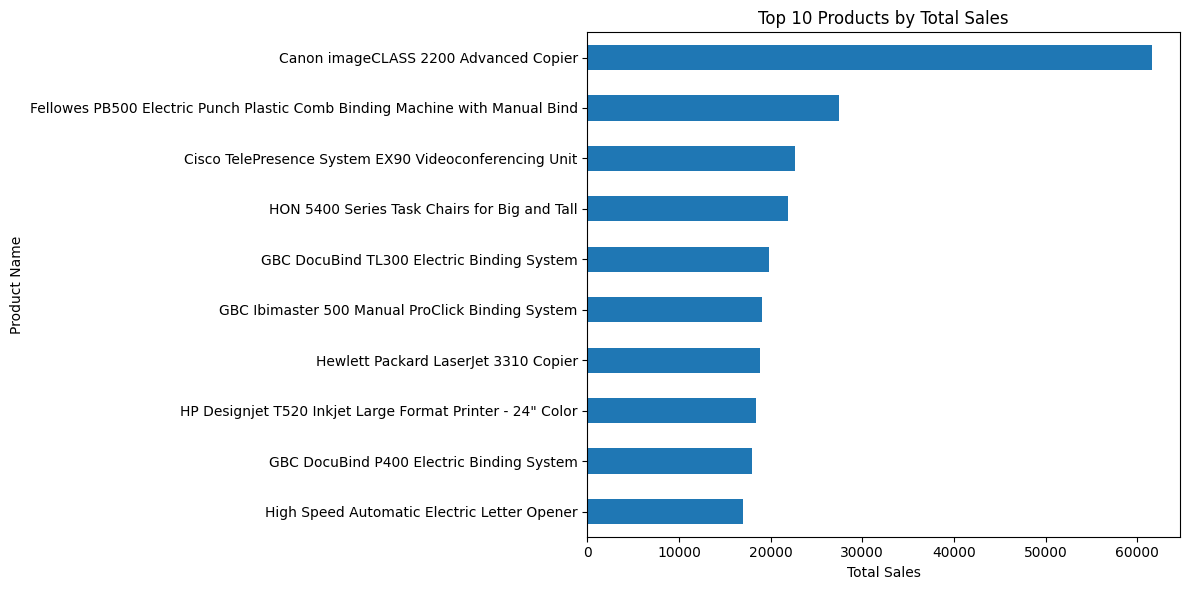

In [157]:

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


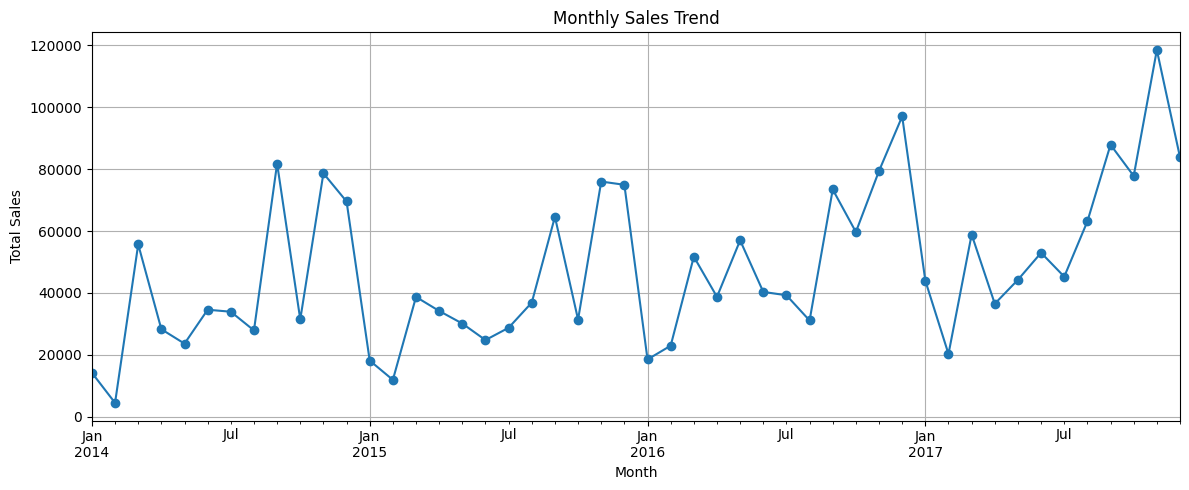

In [158]:

# Convert Order Date to datetime
superstore_df["Order Date"] = pd.to_datetime(
    superstore_df["Order Date"],
    errors="coerce"
)

# Calculate monthly sales
monthly_sales = (
    superstore_df
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

# Plot monthly sales
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()



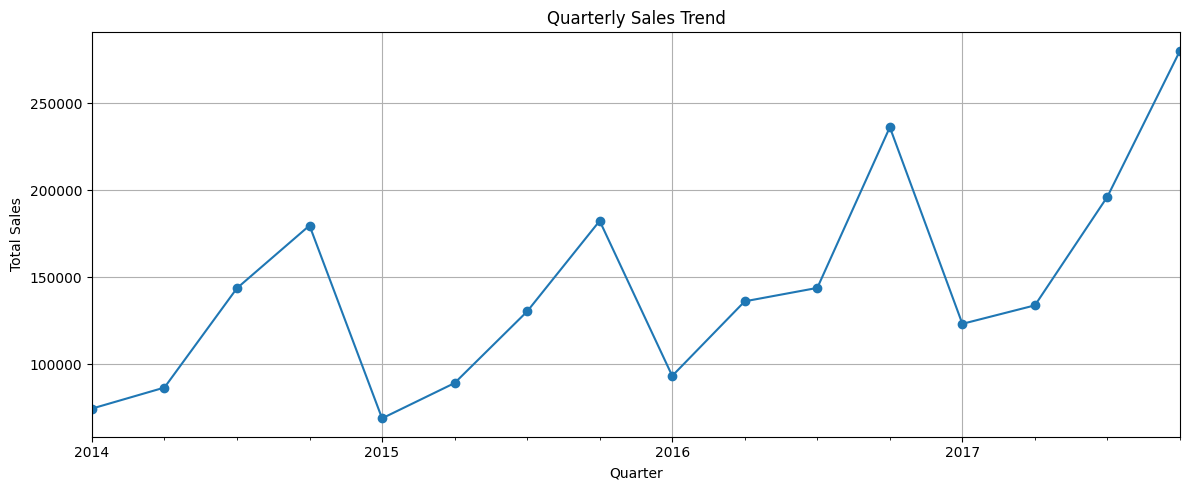

In [159]:

quarterly_sales = (
    superstore_df
    .set_index("Order Date")["Sales"]
    .resample("QS")
    .sum()
)

plt.figure(figsize=(12, 5))
quarterly_sales.plot(kind="line", marker="o")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()


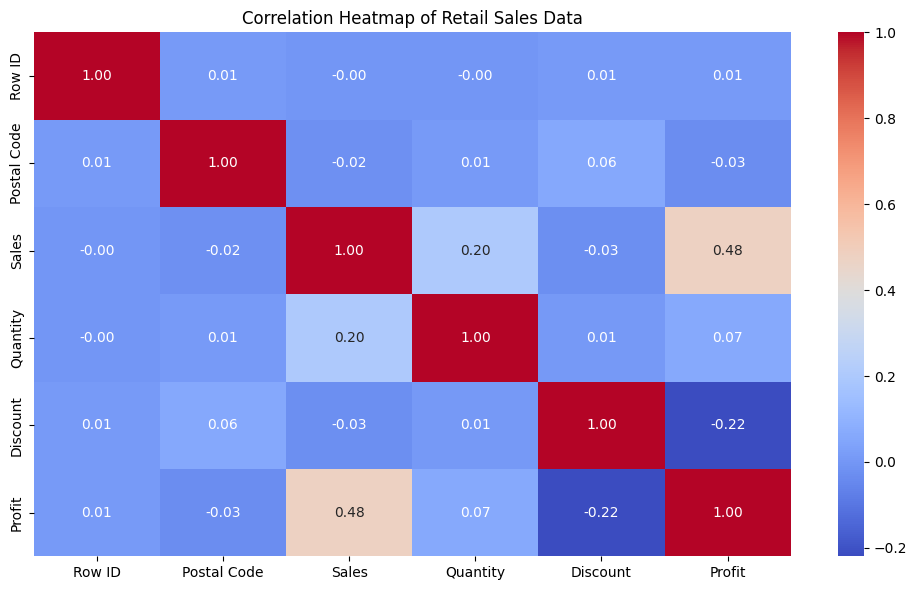

In [160]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

numeric_data = superstore_df.select_dtypes(include="number")
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()


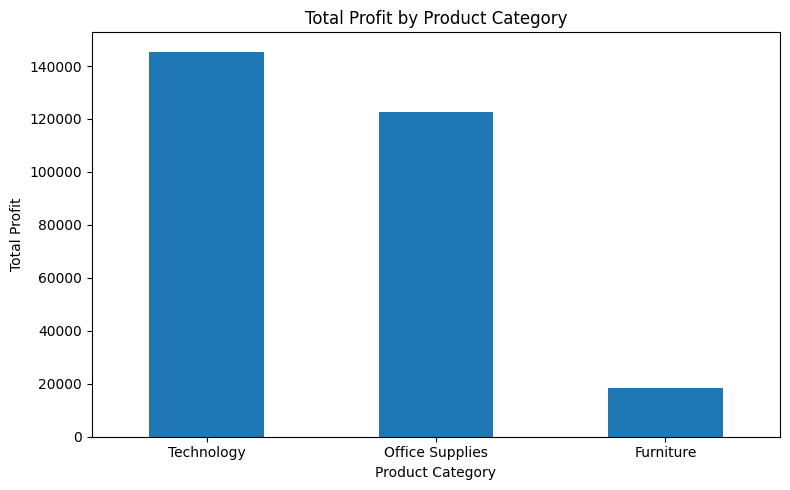

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [161]:

profit_by_category = (
    superstore_df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
profit_by_category.plot(kind="bar")

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(profit_by_category)


In [162]:

print(superstore_df.columns.tolist())


['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [163]:

print(superstore_df.columns.tolist())


['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [164]:

for column in superstore_df.columns:
    print(column)


Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Customer Name
Segment
Country
City
State
Postal Code
Region
Product ID
Category
Sub-Category
Product Name
Sales
Quantity
Discount
Profit


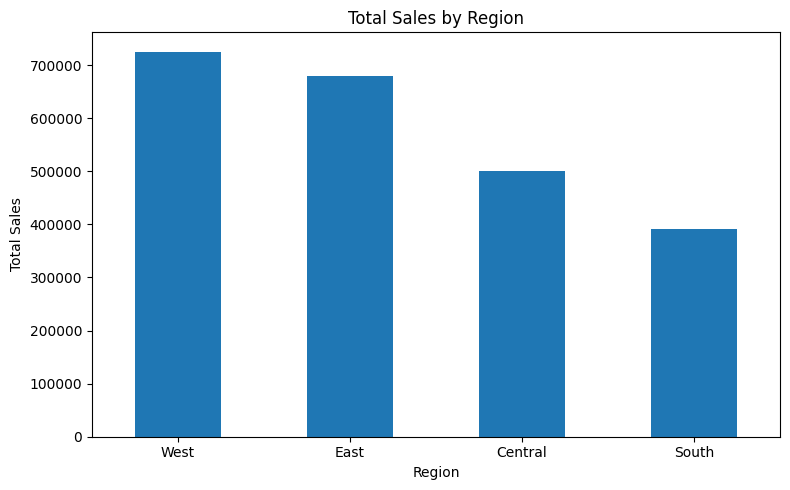

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [165]:

sales_by_region = (
    superstore_df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_region.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(sales_by_region)



## Customer Demographics — Dataset Limitation

The selected Superstore dataset does not contain customer age or gender columns. Therefore, age-group and gender-distribution analysis cannot be performed using this dataset. Instead, customer and regional sales information is analyzed using the available columns. A separate dataset containing age and gender would be required to complete demographic analysis.



## Chart Observations

### Monthly Sales Trend
Monthly sales fluctuate over time, with some months recording higher sales than others.

### Quarterly Sales Trend
Quarterly sales help identify changes in sales performance across three-month periods.

### Correlation Heatmap
The heatmap shows relationships between numerical variables such as Sales, Profit, Quantity, and Discount. Stronger positive or negative values indicate stronger linear relationships.

### Profit by Product Category
The chart compares total profit across product categories and helps identify which categories contribute most to profit.



## Business Recommendations

1. **Focus on Technology Products:** Technology generated the highest total sales in this dataset. The business should review demand and stock levels for popular technology products to reduce stock shortages.

2. **Improve Product Profitability:** Compare profit margins across product categories. Review discounting, costs, and pricing for products that generate high sales but relatively low profit.

3. **Plan for Sales Fluctuations:** Use the monthly and quarterly sales trends to plan inventory and promotional campaigns ahead of periods when demand is typically higher.



## Observations and Insights

### 1. Sales by Product Category
Technology had the highest total sales, at approximately 836,154.03.

### 2. Top 10 Products
Canon imageCLASS 2200 Advanced Copier had the highest total sales among the top 10 products.

### 3. Monthly Sales Trend
Monthly sales fluctuated over time, with some months recording much higher sales than others.

### 4. Quarterly Sales Trend
[Write what you observe from your quarterly sales chart.]

### 5. Correlation Heatmap
[Write one observation about a strong positive or negative correlation.]

### 6. Profit by Product Category
[Write which category had the highest total profit, based on your output.]
